## 341 - Making a Cross-Section with MetPy Part 1

[Youtube](https://www.youtube.com/watch?v=Hv0oNJ6XEn4)

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import metpy.calc as mpcalc

from metpy.interpolate import cross_section
from metpy.units import units
from pathlib import Path
from urllib.request import urlretrieve

In [2]:
date = '20230420'
hour = '00'
forecast_hour = '00'

filename = f'hrrr.t{hour}z.wrfprsf{forecast_hour}.grib2'

url = f'https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr.{date}/conus/{filename}'

Path(filename).parent.mkdir(parents=True, exist_ok=True)

urlretrieve(url, filename)

('hrrr.t00z.wrfprsf00.grib2', <http.client.HTTPMessage at 0x2ad1a87a210>)

In [3]:
ds = xr.open_dataset(filename, engine='cfgrib', filter_by_keys={'typeOfLevel': 'isobaricInhPa'})

Ignoring index file 'hrrr.t00z.wrfprsf00.grib2.5b7b6.idx' older than GRIB file


In [4]:
ds = ds.metpy.parse_cf()

C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\1067152383.py:1: UserWarning: More than one time coordinate present for variable  "gh".
  ds = ds.metpy.parse_cf()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\1067152383.py:1: UserWarning: More than one time coordinate present for variable  "t".
  ds = ds.metpy.parse_cf()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\1067152383.py:1: UserWarning: More than one time coordinate present for variable  "r".
  ds = ds.metpy.parse_cf()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\1067152383.py:1: UserWarning: More than one time coordinate present for variable  "dpt".
  ds = ds.metpy.parse_cf()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\1067152383.py:1: UserWarning: More than one time coordinate present for variable  "q".
  ds = ds.metpy.parse_cf()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\1067152383.py:1: UserWarning: More than one time coordinate present for variable  "w".
  ds = ds.metpy.parse_cf()
C:\Users\jess

In [5]:
ds

<xarray.Dataset> Size: 4GB
Dimensions:        (isobaricInhPa: 40, y: 1059, x: 1799)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 320B 1.013e+03 1e+03 ... 75.0 50.0
    latitude       (y, x) float64 15MB 21.14 21.15 21.15 ... 47.86 47.85 47.84
    longitude      (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.0 299.1
    time           datetime64[ns] 8B 2023-04-20
    step           timedelta64[ns] 8B 00:00:00
    valid_time     datetime64[ns] 8B 2023-04-20
Dimensions without coordinates: y, x
Data variables: (12/14)
    gh             (isobaricInhPa, y, x) float32 305MB ...
    t              (isobaricInhPa, y, x) float32 305MB ...
    r              (isobaricInhPa, y, x) float32 305MB ...
    dpt            (isobaricInhPa, y, x) float32 305MB ...
    q              (isobaricInhPa, y, x) float32 305MB ...
    w              (isobaricInhPa, y, x) float32 305MB ...
    ...             ...
    absv           (isobaricInhPa, y, x) float32 305MB ...
    clwmr          (isobaricInhPa, y, x) float32 305MB ...
    unknown        (isobaricInhPa, y, x) float32 305MB ...
    rwmr           (isobaricInhPa, y, x) float32 305MB ...
    snmr           (isobaricInhPa, y, x) float32 305MB ...
    grle           (isobaricInhPa, y, x) float32 305MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-21T19:24 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
ds = ds.metpy.assign_crs({'grid_mapping_name': 'lambert_conformal_conic', 'latitude_of_projection_origin': 38.5, 'longitude_of_central_meridian': -97.5, 'standard_parallel': [38.5, 38.5], 'earth_radius': 6371229})

ds = ds.metpy.assign_y_x()

C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\3872301418.py:3: UserWarning: More than one time coordinate present for variable  "gh".
  ds = ds.metpy.assign_y_x()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\3872301418.py:3: UserWarning: More than one time coordinate present for variable  "t".
  ds = ds.metpy.assign_y_x()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\3872301418.py:3: UserWarning: More than one time coordinate present for variable  "r".
  ds = ds.metpy.assign_y_x()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\3872301418.py:3: UserWarning: More than one time coordinate present for variable  "dpt".
  ds = ds.metpy.assign_y_x()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\3872301418.py:3: UserWarning: More than one time coordinate present for variable  "q".
  ds = ds.metpy.assign_y_x()
C:\Users\jessi\AppData\Local\Temp\ipykernel_25604\3872301418.py:3: UserWarning: More than one time coordinate present for variable  "w".
  ds = ds.metpy.assign_y_x()
C

In [7]:
ds

<xarray.Dataset> Size: 4GB
Dimensions:        (isobaricInhPa: 40, y: 1059, x: 1799)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 320B 1.013e+03 1e+03 ... 75.0 50.0
  * y              (y) float64 8kB -1.587e+06 -1.584e+06 ... 1.584e+06 1.587e+06
  * x              (x) float64 14kB -2.698e+06 -2.695e+06 ... 2.696e+06
    latitude       (y, x) float64 15MB 21.14 21.15 21.15 ... 47.86 47.85 47.84
    longitude      (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.0 299.1
    time           datetime64[ns] 8B 2023-04-20
    step           timedelta64[ns] 8B 00:00:00
    valid_time     datetime64[ns] 8B 2023-04-20
    metpy_crs      object 8B Projection: lambert_conformal_conic
Data variables: (12/14)
    gh             (isobaricInhPa, y, x) float32 305MB ...
    t              (isobaricInhPa, y, x) float32 305MB ...
    r              (isobaricInhPa, y, x) float32 305MB ...
    dpt            (isobaricInhPa, y, x) float32 305MB ...
    q              (isobaricInhPa, y, x) float32 305MB ...
    w              (isobaricInhPa, y, x) float32 305MB ...
    ...             ...
    absv           (isobaricInhPa, y, x) float32 305MB ...
    clwmr          (isobaricInhPa, y, x) float32 305MB ...
    unknown        (isobaricInhPa, y, x) float32 305MB ...
    rwmr           (isobaricInhPa, y, x) float32 305MB ...
    snmr           (isobaricInhPa, y, x) float32 305MB ...
    grle           (isobaricInhPa, y, x) float32 305MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-21T19:24 GRIB to CDM+CF via cfgrib-0.9.1...

In [8]:
start = (30, -97.2)
end = (45, -97.2)

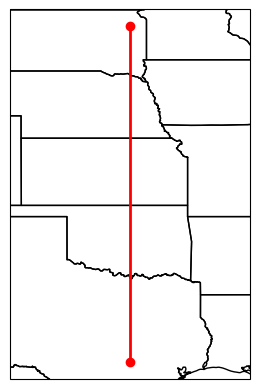

In [9]:
fig = plt.figure()
ax = plt.axes(projection = ccrs.PlateCarree())

ax.add_feature(cfeature.STATES)

ax.plot([start[1], end[1]], [start[0], end[0]], color = 'red', linewidth=2, marker='o', transform=ccrs.PlateCarree())